# Active GLiNER: Named entities (NER)

The task: find names and other short spans in a text, each with a type. For example, *"show me films with drew barrymore from the 1980s"* gives `drew barrymore` = actor and `1980s` = year.

This notebook follows the recipe from the paper:

```
your unlabelled texts
   │  1. the untrained student ranks them once, least sure first
   ▼
top N texts ──> a random quarter: human labels
           └──> the rest: LLM labels
   │  2. train the student on both (LoRA)
   ▼
a small, fast model you own ──> 3. check it on labelled dev data ──> 4. predict
```

Data: MIT Movie: questions about films, 12 entity types. The "human" labels here come from the dataset's own annotators, so you
can see the recipe end to end without labelling anything yourself.

You need a GPU (8 GB is enough) and an OpenAI-compatible LLM server. This repository
starts Gemma 4 12B with `scripts/serve_teacher_gemma.sh`; any other local or hosted
endpoint works too.

In [1]:
import json
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display

from active_gliner import byod, data, tasks

TASK = "ner"
DATASET = "mit_movie"
TEACHER_URL = "http://127.0.0.1:8020/v1"
TEACHER_MODEL = "gemma-4-12b-qat"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## 1. Your data

The tool reads JSONL files, one text per line:

+ `texts.jsonl` - unlabelled texts (`text`, and for relations the `entities` list).
+ `dev.jsonl` - a few hundred texts with correct labels, to measure accuracy.

Here we write both from the dataset.

In [2]:
demo = Path("demo-ner")
demo.mkdir(exist_ok=True)
splits = data.load(DATASET)
names = tasks.labels(DATASET, splits)  # label code -> label name


def write(path, records, with_labels):
    rows = [byod.record_to_row(r, names, with_labels) for r in records]
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows))


write(demo / "texts.jsonl", splits["pool"][:5000], with_labels=False)
write(demo / "dev.jsonl", splits["dev"][:300], with_labels=True)
labels = ",".join(names.values())
print(len(names), "labels:", labels[:200], "...")
print(open(demo / "dev.jsonl").readline()[:300])

12 labels: actor,character,director,genre,plot,rating,ratings average,review,song,title,trailer,year ...
{"id": "mit_movie:en-US:train-1", "text": "show me films with drew barrymore from the 1980s", "entities": [{"text": "drew barrymore", "start": 19, "end": 33, "label": "actor"}, {"text": "1980s", "start": 43, "end": 48, "label": "year"}]}



## 2. What the untrained student does

GLiNER2.5 already works for any label names, with no training. This is the score to beat.

In [3]:
task = tasks.for_dataset(DATASET)
dev = byod.read_labelled(demo / "dev.jsonl", TASK)
label_map = byod.parse_labels(labels)
student = byod.load_student(TASK, label_map)
zero_shot_f1 = task.score(dev, task.predict(student, dev, label_map), label_map)["micro"]["f1"]
print(f"Zero-shot dev F1: {100 * zero_shot_f1:.1f}")
del student
torch.cuda.empty_cache()

Zero-shot dev F1: 47.4


## 3. Rank once and split between humans and the LLM

`rank` scores every text with the untrained student, takes the 1,000 it is least sure
about (texts where it finds nothing go last), and puts a random quarter of them in
`for_humans.jsonl`. The rest goes in `for_llm.jsonl`.

From a terminal:

```bash
active-gliner rank --texts demo/texts.jsonl --task ner --labels "..." \
  --n 1000 --human-share 0.25 --out demo/rank
```

In [4]:
ranked = byod.rank(
    demo / "texts.jsonl", TASK, labels, n=1000, human_share=0.25, out_dir=demo / "rank"
)
for_humans = [json.loads(line) for line in (ranked / "for_humans.jsonl").open()]
for_llm = [json.loads(line) for line in (ranked / "for_llm.jsonl").open()]
print(len(for_humans), "texts for humans,", len(for_llm), "for the LLM")
print("example for a human:", for_humans[0]["text"][:200])

250 texts for humans, 750 for the LLM
example for a human: what philip noyce film had denzel washington in it


## 4. Human labels

In real use, people label `for_humans.jsonl` by hand, in the same format as `dev.jsonl`.
Here we copy the dataset's own labels for those texts.

In [5]:
by_id = {r.id: r for r in splits["pool"]}
write(demo / "human.jsonl", [by_id[row["id"]] for row in for_humans], with_labels=True)
print(open(demo / "human.jsonl").readline()[:300])

{"id": "mit_movie:en-US:train-3379", "text": "what philip noyce film had denzel washington in it", "entities": [{"text": "denzel washington", "start": 27, "end": 44, "label": "actor"}]}



## 5. LLM labels for the rest, then train

`fit` sends every text in `for_llm.jsonl` to the LLM (`select="all"`), checks every
answer (valid JSON, allowed labels, exact text spans), adds the human-labelled texts,
and trains a LoRA adapter. The LLM never sees the human-labelled texts.

```bash
active-gliner fit --texts demo/rank/for_llm.jsonl --select all --human demo/human.jsonl \
  --task ner --labels "..." --dev demo/dev.jsonl \
  --teacher-url http://127.0.0.1:8020/v1 --teacher-model gemma-4-12b-qat --out demo/run
```

For a hosted API, also pass `api_key_env="NAME_OF_THE_KEY_VARIABLE"`.

In [6]:
run = byod.fit(
    texts=ranked / "for_llm.jsonl",
    task=TASK,
    labels=labels,
    teacher_url=TEACHER_URL,
    teacher_model=TEACHER_MODEL,
    select="all",
    human=demo / "human.jsonl",
    dev=demo / "dev.jsonl",
    out_dir=demo / "run",
)
print(run)

demo-ner/run


## 6. Check the result

Every run folder holds plain files: a one-page report, training curves, every LLM label
and every wrong prediction.

In [7]:
metrics = json.loads((run / "metrics.json").read_text())
trained_f1 = metrics["dev"]["micro"]["f1"]
print(f"Dev F1: zero-shot {100 * zero_shot_f1:.1f} -> trained {100 * trained_f1:.1f}")
print("LLM answers:", json.loads((run / "teacher_stats.json").read_text()))

Dev F1: zero-shot 47.4 -> trained 74.6
LLM answers: {'elapsed_s': 218.54246021411382, 'workers': 8, 'gpu_shared': False, 'requests': 750, 'cache_hits': 0, 'retries': 0, 'duplicate': 0, 'prompt_tokens': 191973, 'completion_tokens': 42114, 'latency_s_total': 1740.817340443842, 'errors_by_kind': {'not_in_text': 6, 'not_on_word_edges': 11}, 'invalid_records': 14, 'valid_rate': 0.9813333333333333, 'cost_usd': 0.0}


In [8]:
display(Markdown((run / "report.md").read_text()))

# user: all, N=750, seed=1

Locale: en-US. Labels: custom. LoRA r=32, alpha=64.0, task LR=0.00030971254911697343. Augmentation: False.
Acquisition threshold: 0.5. Evaluation threshold: 0.5.

| Split | Micro F1 | Macro F1 |
| --- | ---: | ---: |
| dev | 0.7455 | 0.6047 |

Best step: 800. Stop reason: max_steps.
Wall time: 341.98 s. Training time: 109.22 s.

| Type | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| actor | 0.8539 | 0.9500 | 0.8994 | 80 |
| character | 0.7692 | 0.6897 | 0.7273 | 29 |
| director | 0.8846 | 0.7931 | 0.8364 | 29 |
| genre | 0.7500 | 0.7397 | 0.7448 | 73 |
| plot | 0.5312 | 0.3036 | 0.3864 | 56 |
| rating | 0.6250 | 0.5882 | 0.6061 | 17 |
| ratings average | 0.0000 | 0.0000 | 0.0000 | 19 |
| review | 0.0000 | 0.0000 | 0.0000 | 13 |
| song | 1.0000 | 0.5455 | 0.7059 | 22 |
| title | 0.8673 | 0.8673 | 0.8673 | 98 |
| trailer | 1.0000 | 0.4286 | 0.6000 | 7 |
| year | 0.8947 | 0.8718 | 0.8831 | 39 |

[Training curves](plots/training_curves.png) · [Calibration](plots/calibration.png) · [Errors](errors.jsonl)

Extraction calibration includes emitted predictions only; low bins can be empty because of the evaluation threshold. Classification includes all label probabilities.


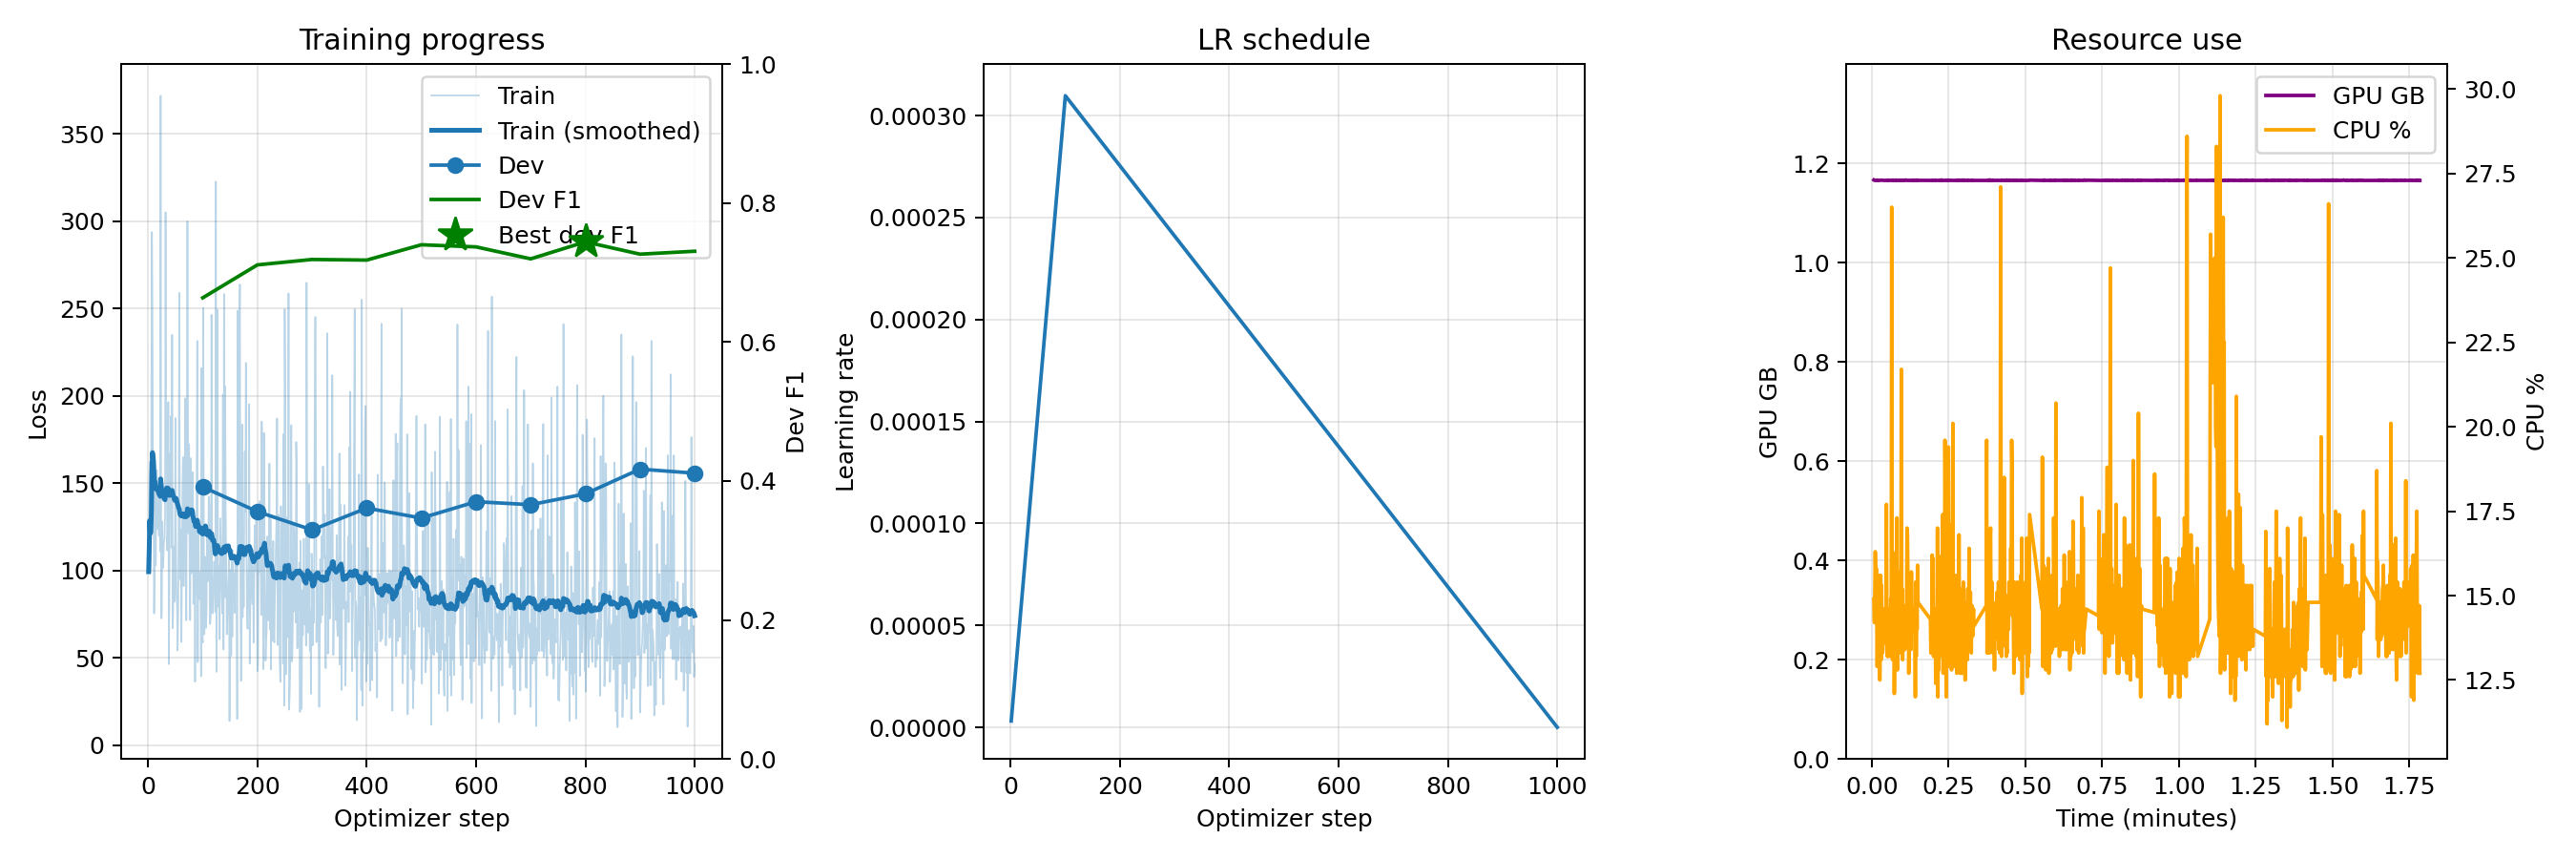

In [9]:
display(Image(filename=str(run / "plots" / "training_curves.png")))

## 7. Use the trained model

`predict` loads the adapter and runs on a GPU or a CPU:

```bash
active-gliner predict --adapter demo/run/adapter/best --task ner --labels "..." \
  --texts new.jsonl
```

In [10]:
new = [
    "who directed the dark knight",
    "any good horror movies from 1978 with jamie lee curtis",
    "play the trailer for the new pixar film",
]
(demo / "new.jsonl").write_text("".join(json.dumps({"text": t}) + "\n" for t in new))
predictions = byod.predict(run / "adapter" / "best", TASK, labels, demo / "new.jsonl")
for text, prediction in zip(new, predictions, strict=True):
    print(text)
    print("   ", [(s["text"], s["label"]) for s in prediction["spans"]])

who directed the dark knight
    [('the dark knight', 'title')]
any good horror movies from 1978 with jamie lee curtis
    [('horror', 'genre'), ('1978', 'year'), ('jamie lee curtis', 'actor')]
play the trailer for the new pixar film
    [('pixar', 'title')]


## What the paper found for this task

On our four NER datasets, LLM labels for a quarter of the inputs cost under two F1 points, and a quarter or fewer human labels beat the LLM itself on most datasets.

See the paper (`paper/main.pdf`, Section 4.4) for the numbers on every dataset.